# Лабораторна робота №2
## PCA, кластеризація та класифікація текстів

**Мета:** Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.

Використаємо URL-датасет із Lab 1 для першої й другої частин, а [Fake.csv](https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset) — для текстової класифікації.

## Імпорт бібліотек

In [52]:
from pathlib import Path
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.svm import SVC, LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, silhouette_score, adjusted_rand_score, precision_recall_fscore_support

sns.set_theme(style='whitegrid', font='DejaVu Sans')
RANDOM_STATE = 69


data_dir = next(path for path in [Path('data'), Path('../data')]
                 if (path / 'Fake.csv').exists())

# 1. Зменшення розмірності та візуалізація URL

### 1.1 Підготовка даних
Використано **PhiUSIIL Phishing URL Dataset** із Lab 1. Мітка `0` означає фішинговий, `1` — легітимний URL.

Для PCA та порівняння SVM використано **всі 50 числових ознак датасету та категоріальну ознаку `TLD`**. 

Виключено `label` (ціль), а також сирі текстові поля `URL`, `Domain`, `Title`, `FILENAME`.

Числові ознаки стандартизовано, `TLD` закодовано one-hot. Після кодування отримано 295 стовпців. `StandardScaler`, `OneHotEncoder`.

In [2]:
url_df = pd.read_csv(data_dir / 'PhiUSIIL_Phishing_URL_Dataset.csv', encoding='utf-8-sig')

# Усі числові ознаки та категоріальна ознака TLD.
# Target і сирі текстові поля не входять до PCA.
excluded_columns = ['label', 'FILENAME', 'URL', 'Domain', 'Title']
features = [column for column in url_df.columns if column not in excluded_columns]

url_df = url_df.drop_duplicates(subset='URL').dropna(subset=features + ['label'])
sample = pd.concat([
    group.sample(min(len(group), 5000), random_state=RANDOM_STATE)
    for _, group in url_df.groupby('label')
], ignore_index=True)

X = sample[features]
y = sample['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

numeric_features = X.select_dtypes(include='number').columns.tolist()
preprocessor = ColumnTransformer([
    ('numbers', StandardScaler(), numeric_features),
    ('tld', OneHotEncoder(handle_unknown='ignore'), ['TLD'])
])
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print(f'Навчальних прикладів: {len(y_train):,}')
print(f'Тестових прикладів: {len(y_test):,}')
print(f'Ознак після кодування TLD: {X_train_ready.shape[1]}')

Навчальних прикладів: 7,500
Тестових прикладів: 2,500
Ознак після кодування TLD: 295


### 1.2 Пояснена дисперсія компонент
Перед оцінюванням класифікатора подивимося, яку частку дисперсії зберігає кожна головна компонента. Пунктирна крива показує накопичену дисперсію; горизонтальні лінії позначають пороги 90% і 95%.

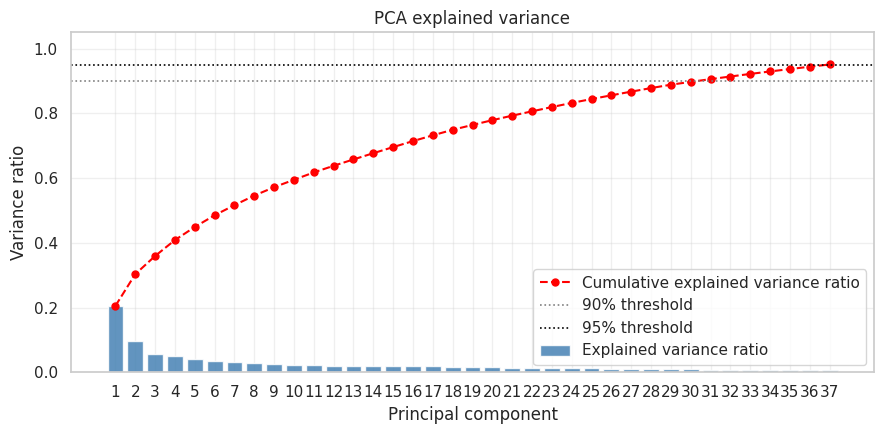

95% дисперсії досягається за 37 компонент


In [13]:
# Повний PCA потрібен тут лише для аналізу частки дисперсії компонент.
pca_variance = PCA(random_state=RANDOM_STATE)
pca_variance.fit(X_train_ready.toarray())

explained = pca_variance.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components_95 = np.searchsorted(cumulative, 0.95) + 1
components_to_show = np.arange(1, n_components_95 + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(components_to_show, explained[:n_components_95],
       color='steelblue', alpha=0.85, label='Explained variance ratio')
ax.plot(components_to_show, cumulative[:n_components_95], 'o--',
        color='red', markersize=5, label='Cumulative explained variance ratio')
ax.axhline(0.90, color='gray', linestyle=':', linewidth=1.2, label='90% threshold')
ax.axhline(0.95, color='black', linestyle=':', linewidth=1.2, label='95% threshold')
ax.set_title('PCA explained variance')
ax.set_xlabel('Principal component')
ax.set_ylabel('Variance ratio')
ax.set_xticks(components_to_show)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'95% дисперсії досягається за {n_components_95} компонент')

### 1.3 PCA і якість класифікації
PCA збереже 95% дисперсії даних. Порівняємо кількість ознак, якість класифікації та час навчання SVM.

In [14]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_ready.toarray())
X_test_pca = pca.transform(X_test_ready.toarray())

results = []
for name, train_data, test_data in [
    ('До PCA', X_train_ready, X_test_ready),
    ('Після PCA', X_train_pca, X_test_pca)
]:
    model = SVC(kernel='rbf', C=10, gamma='scale')
    start = time.perf_counter()
    model.fit(train_data, y_train)
    train_seconds = time.perf_counter() - start
    prediction = model.predict(test_data)
    results.append({
        'Варіант': name,
        'Ознак': train_data.shape[1],
        'Accuracy': accuracy_score(y_test, prediction),
        'Macro F1': f1_score(y_test, prediction, average='macro'),
        'Час навчання, с': train_seconds
    })

comparison = pd.DataFrame(results)
display(comparison.round(3))
print(f'PCA зберіг {pca.explained_variance_ratio_.sum():.1%} дисперсії')
print(f'Кількість ознак скоротилася з {X_train_ready.shape[1]} до {pca.n_components_}')


,Варіант,Ознак,Accuracy,Macro F1,"Час навчання, с"
0,До PCA,295,0.998,0.998,0.354
1,Після PCA,37,0.999,0.999,0.120


PCA зберіг 95.1% дисперсії
Кількість ознак скоротилася з 295 до 37


### Результат PCA
На вхід PCA подано всі **295 стовпців після масштабування 50 числових ознак та one-hot кодування `TLD`**. Після PCA залишилося **37 компонент**, які зберігають **95,1% дисперсії** навчальних даних.

### 1.3 t-SNE у двох вимірах
Кожна точка - URL, колір — відомий клас. t-SNE будує карту схожості точок; 

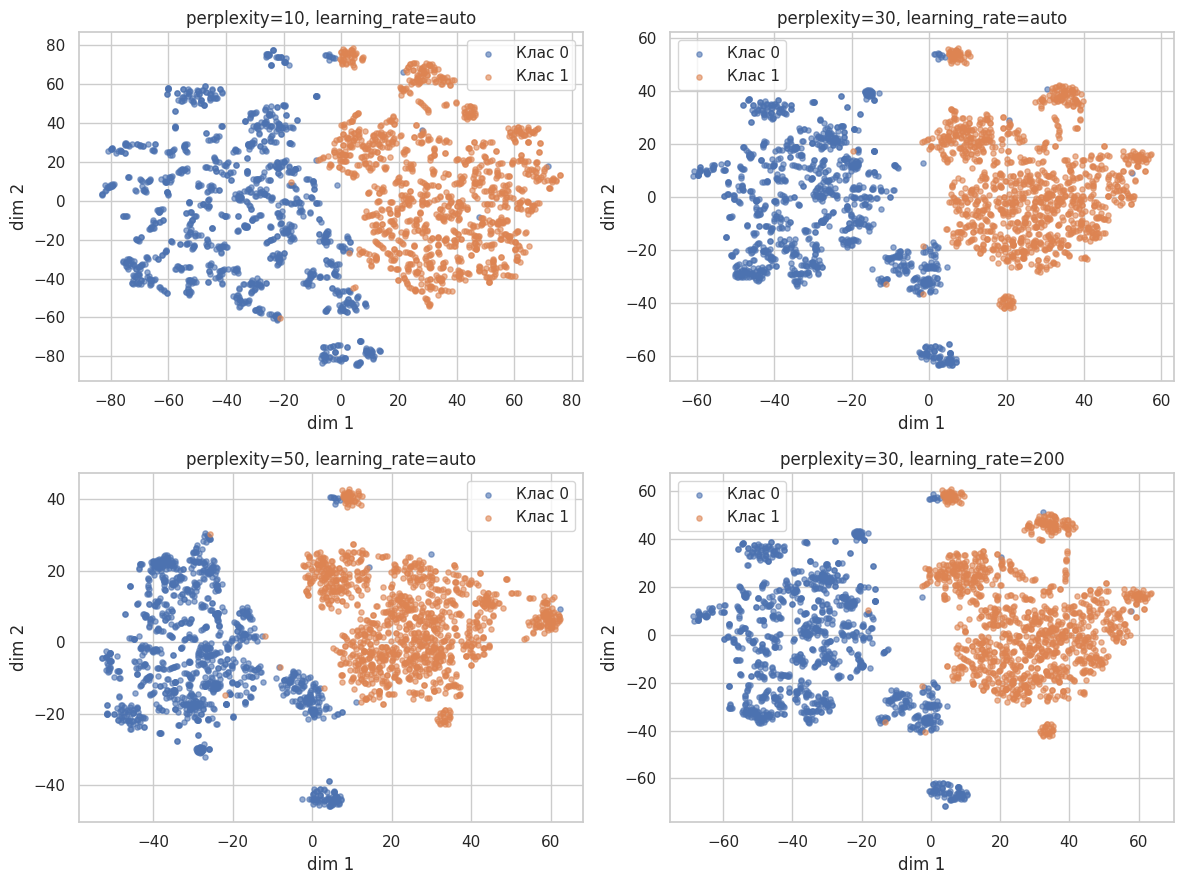

In [24]:
rng = np.random.RandomState(RANDOM_STATE)
chosen = rng.choice(len(y_test), size=min(5000, len(y_test)), replace=False)
X_tsne_input = X_test_ready[chosen].toarray()
y_tsne = y_test.iloc[chosen].to_numpy()

# Порівняння кількох параметрів t-SNE на однаковій вибірці
tsne_configs = [
    {'perplexity': 10, 'learning_rate': 'auto', 'init': 'pca'},
    {'perplexity': 30,  'learning_rate': 'auto', 'init': 'pca'},
    {'perplexity': 50, 'learning_rate': 'auto', 'init': 'pca'},
    {'perplexity': 30, 'learning_rate': 200, 'init': 'pca'},
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, config in zip(axes.flat, tsne_configs):
    X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE,
                  **config).fit_transform(X_tsne_input)
    for label in sorted(y.unique()):
        mask = y_tsne == label
        ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=14, alpha=0.6,
                   label=f'Клас {label}')
    ax.set(title=f"perplexity={config['perplexity']}, learning_rate={config['learning_rate']}",
           xlabel='dim 1', ylabel='dim 2')
    ax.legend()
plt.tight_layout()
plt.show()


Сині точки — фішингові URL (0), помаранчеві — легітимні (1). На поточному графіку сині точки переважно зліва, помаранчеві — справа; є окремі невеликі групи та поодинокі точки іншого класу всередині груп.

Мітки не використовувалися під час навчання t-SNE, а лише для кольорів. Метод відображає насамперед локальні сусідства: відстані між далекими групами, їхні розміри й орієнтація осей не мають прямої інтерпретації в початковому просторі.

# 2. Кластеризація URL
Кластеризація не використовує `label`: алгоритм сам шукає групи схожих спостережень. Після вибору кластерів зіставимо їх зі справжніми класами.

In [28]:
cluster_sample = url_df.sample(n=min(2000, len(url_df)), random_state=RANDOM_STATE)
cluster_features = ['URLLength', 'DomainLength', 'NoOfSubDomain', 'IsHTTPS',
                    'CharContinuationRate', 'TLD']
X_cluster = cluster_sample[cluster_features]
y_cluster = cluster_sample['label']  # збережено лише для аналізу після кластеризації
cluster_preprocessor = ColumnTransformer([
    ('numbers', StandardScaler(), X_cluster.select_dtypes(include='number').columns),
    ('tld', OneHotEncoder(handle_unknown='ignore'), ['TLD'])
])
X_cluster_ready = cluster_preprocessor.fit_transform(X_cluster).toarray()

scores = []
for k in range(2, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_cluster_ready)
    scores.append({'k': k, 'Inertia': model.inertia_,
                  'Silhouette': silhouette_score(X_cluster_ready, labels)})
scores = pd.DataFrame(scores)
display(scores.round(3))

,k,Inertia,Silhouette
0,2,8721.970,0.335
1,3,7013.356,0.355
2,4,6043.158,0.335
3,5,5160.072,0.342
4,6,4665.797,0.365
5,7,4271.672,0.371
6,8,3965.777,0.305
7,9,3672.929,0.317


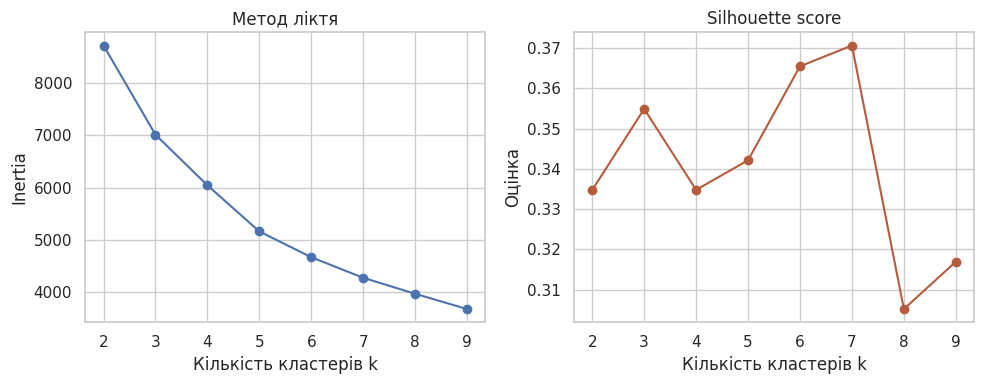

Для подальшого аналізу обрано k = 7


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(scores['k'], scores['Inertia'], marker='o')
axes[0].set(title='Метод ліктя', xlabel='Кількість кластерів k', ylabel='Inertia')
axes[1].plot(scores['k'], scores['Silhouette'], marker='o', color='#b65b3b')
axes[1].set(title='Silhouette score', xlabel='Кількість кластерів k', ylabel='Оцінка')
plt.tight_layout()
plt.show()

best_k = int(scores.loc[scores['Silhouette'].idxmax(), 'k'])
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_cluster_ready)
print(f'Для подальшого аналізу обрано k = {best_k}')

Обрано 7 кластерів, оскільки при \(k = 7\) досягається найвище значення Silhouette score (≈ 0.37), що свідчить про найкраще співвідношення компактності кластерів та їх відокремленості.

### Кластери і порівняти зі справжніми класами

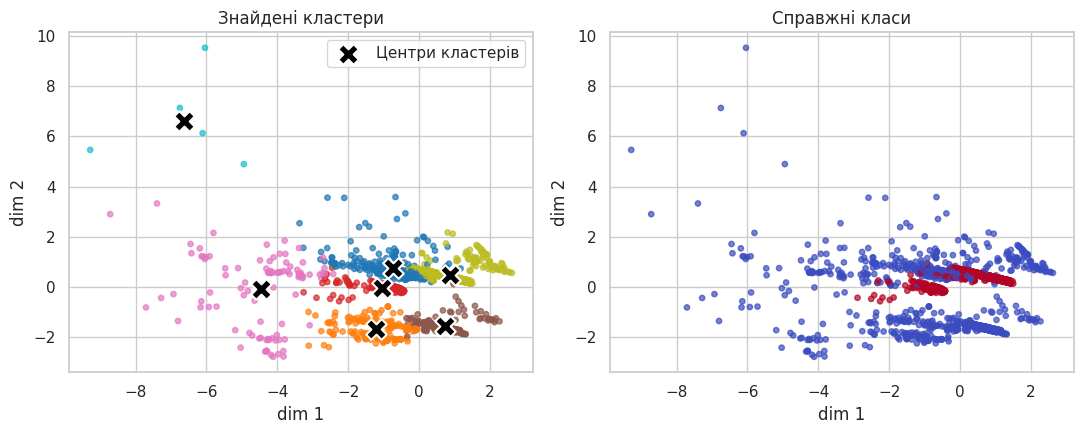

Справжній клас,0,1
Кластер,,
0,225,66
1,154,0
2,19,153
3,274,0
4,103,0
5,109,892
6,5,0


ARI = 0.373


In [31]:
# PCA тут потрібен лише для 2D-картинки; K-Means навчався на всіх ознаках
pca_cluster_plot = PCA(n_components=2, random_state=RANDOM_STATE)
cluster_2d = pca_cluster_plot.fit_transform(X_cluster_ready)
centers_2d = pca_cluster_plot.transform(kmeans.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(cluster_2d[:, 0], cluster_2d[:, 1], c=cluster_labels,
                cmap='tab10', s=15, alpha=0.7)
axes[0].scatter(centers_2d[:, 0], centers_2d[:, 1], marker='X',
                s=220, c='black', edgecolors='white', linewidths=1.5,
                label='Центри кластерів')
axes[0].set_title('Знайдені кластери')
axes[0].legend()
axes[1].scatter(cluster_2d[:, 0], cluster_2d[:, 1], c=y_cluster,
                cmap='coolwarm', s=15, alpha=0.7)
axes[1].set_title('Справжні класи')
for ax in axes:
    ax.set_xlabel('dim 1')
    ax.set_ylabel('dim 2')
plt.tight_layout()
plt.show()

display(pd.crosstab(cluster_labels, y_cluster,
                    rownames=['Кластер'], colnames=['Справжній клас']))
print(f'ARI = {adjusted_rand_score(y_cluster, cluster_labels):.3f}')

 На кривій inertia немає єдиного різко вираженого ліктя.

Кластери 1, 3, 4 і 6 містять лише фішингові URL (154, 274, 103 і 5 спостережень). У кластері 0 переважає фішинг: 225 із 291, або 77,3%. У кластерах 2 і 5 переважають легітимні URL: відповідно 153 із 172 (89,0%) та 892 із 1001 (89,1%). Отже, ознаки частково розділяють класи, проте один клас розпадається на кілька геометричних груп; також залишаються змішані кластери.

ARI (Adjusted Rand Index) — це метрика, яка оцінює, наскільки знайдені алгоритмом кластери збігаються зі справжніми класами.
**ARI = 0,373** свідчить про часткову узгодженість кластерів із класами. ARI порівнює розбиття незалежно від нумерації кластерів і коригує випадкову узгодженість: 1 означає повний збіг, близько 0 — рівень випадкового розбиття, можливі й від’ємні значення.

K-Means мінімізує квадрати евклідових відстаней і шукає компактні групи за вибраними ознаками.

# 3. Класифікація текстів
Використано `Fake.csv`
Тексти з колонки `text`, мітки — з `subject`. Обрано три найчисельніші категорії (`News`, `politics`, `left-news`).

In [35]:
news_df = pd.read_csv(data_dir / 'Fake.csv')
subject_counts = news_df['subject'].value_counts()
topics = subject_counts.head(3).index.tolist()

print(f'Розмір датасету: {news_df.shape[0]:,} рядків × {news_df.shape[1]} стовпців')
print('Стовпці:', ', '.join(news_df.columns))
print('Пропущені значення:')
display(news_df.isna().sum().rename('Кількість пропусків').to_frame())
print('Кількість текстів за категоріями:')
display(subject_counts.rename_axis('Категорія').to_frame('Кількість текстів'))
print('Обрано три найчисельніші категорії:', ', '.join(topics))

Розмір датасету: 23,481 рядків × 4 стовпців
Стовпці: title, text, subject, date
Пропущені значення:


,Кількість пропусків
title,0
text,0
subject,0
date,0


Кількість текстів за категоріями:


,Кількість текстів
Категорія,
News,9050
politics,6841
left-news,4459
Government News,1570
US_News,783
Middle-east,778


Обрано три найчисельніші категорії: News, politics, left-news


### 3.1 Очищення текстів і поділ даних
Текст переводиться в нижній регістр. ВИлучаємо посилання, пунктуацію й цифри. Залишаємо тільки англійські слова довжиною від двох символів, із яких видаляються стоп-слова. Порожні тексти й точні дублікати очищених текстів вилучаються до поділу. Поділ 80/20 .

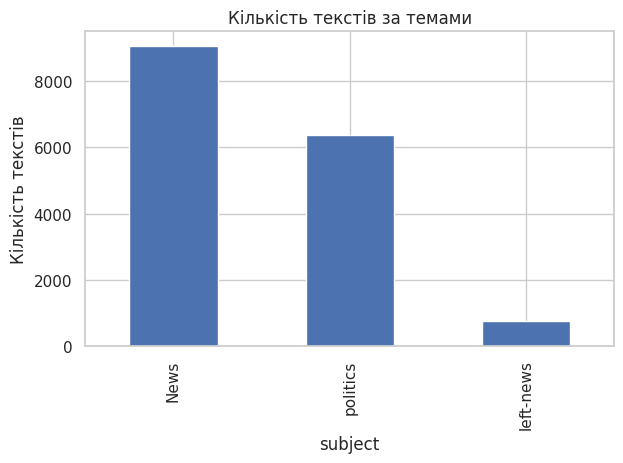

In [49]:
news_df = pd.read_csv(data_dir / 'Fake.csv')
topics = news_df['subject'].value_counts().head(3).index
news = news_df[news_df['subject'].isin(topics)].dropna(subset=['text', 'subject']).copy()
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = re.sub(r'https?://\S+|www\.\S+', ' ', str(text).lower())
    words = re.findall(r'[a-z]{2,}', text)  # лишаємо англійські слова
    return ' '.join(word for word in words if word not in stop_words)

news['clean_text'] = news['text'].map(clean_text)
news = news[news['clean_text'].str.len() > 0].drop_duplicates('clean_text')

X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    news['clean_text'], news['subject'], test_size=0.2,
    stratify=news['subject'], random_state=RANDOM_STATE
)

news['subject'].value_counts().plot(kind='bar', title='Кількість текстів за темами')
plt.ylabel('Кількість текстів')
plt.tight_layout()
plt.show()

### 3.2 TF-IDF і характерні слова
TF-IDF перетворює текст на числа: важливі для окремого тексту слова отримують більшу вагу. Словник навчається тільки на навчальній вибірці.

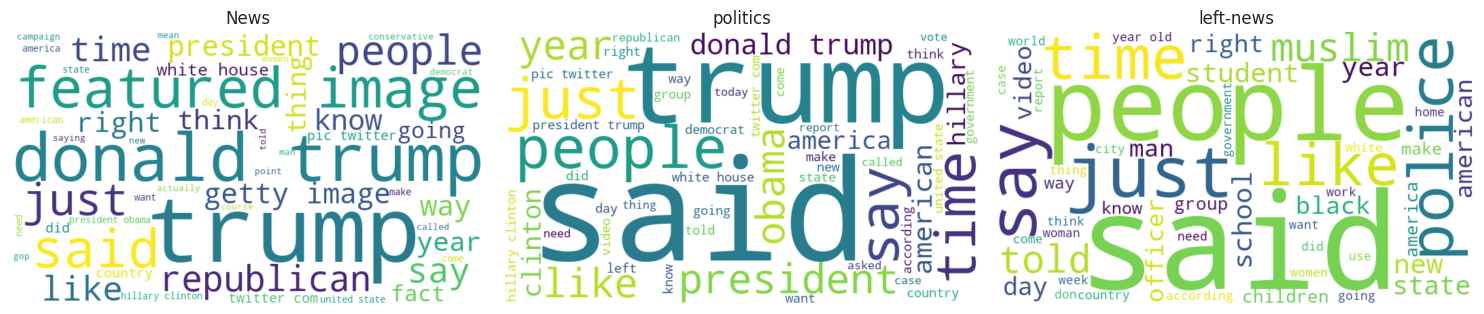

In [50]:
vectorizer = TfidfVectorizer(max_features=10000, min_df=2, stop_words='english')
X_text_train_tfidf = vectorizer.fit_transform(X_text_train)
X_text_test_tfidf = vectorizer.transform(X_text_test)
terms = vectorizer.get_feature_names_out()

fig, axes = plt.subplots(1, len(topics), figsize=(15, 4))
for topic, ax in zip(topics, axes):
    topic_text = ' '.join(X_text_train[y_text_train == topic])
    cloud = WordCloud(width=700, height=400, background_color='white',
                      stopwords=stop_words, max_words=50,
                      random_state=RANDOM_STATE).generate(topic_text)
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(topic)
    ax.axis('off')
plt.tight_layout()
plt.show()

Для News помітні trump, donald trump, republican, а також featured image і getty image

для politics — trump, president, obama, hillary clinton;

для left-news — people, police school, children, muslim. 

Це узгоджується з політичною лексикою перших двох категорій та суспільною тематикою третьої. Водночас  є слова які травпляють в декількох темах: `trump`, `said`, `people`, `time`. Тому одного частого слова недостатньо для надійного розрізнення класів.


### 3.3 Навчання моделі

,Модель,Accuracy,Macro F1
0,Базова,0.559,0.239
1,TF-IDF + LinearSVC,0.923,0.730


,Категорія,Precision,Recall,F1,Кількість тестових текстів
0,News,0.976,0.980,0.978,1810
1,politics,0.895,0.923,0.909,1273
2,left-news,0.371,0.255,0.302,153


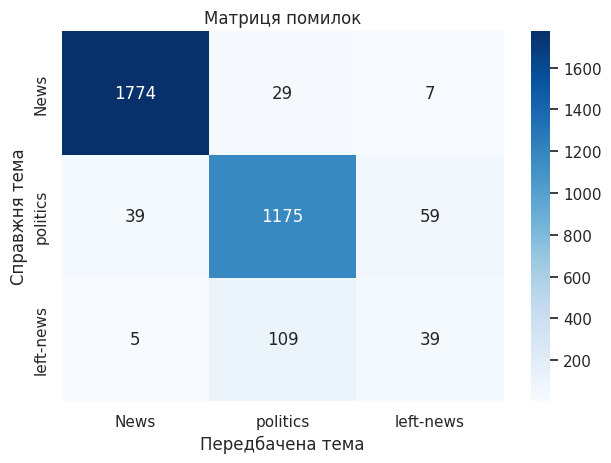

In [ ]:
model = LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)
model.fit(X_text_train_tfidf, y_text_train)
text_prediction = model.predict(X_text_test_tfidf)

baseline = DummyClassifier(strategy='most_frequent').fit(X_text_train_tfidf, y_text_train)
baseline_prediction = baseline.predict(X_text_test_tfidf)
metrics = pd.DataFrame([
    {'Модель': 'Базова', 'Accuracy': accuracy_score(y_text_test, baseline_prediction),
     'Macro F1': f1_score(y_text_test, baseline_prediction, average='macro')},
    {'Модель': 'TF-IDF + LinearSVC', 'Accuracy': accuracy_score(y_text_test, text_prediction),
     'Macro F1': f1_score(y_text_test, text_prediction, average='macro')}
])
display(metrics.round(3))


class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(
    y_text_test, text_prediction, labels=topics, zero_division=0
)
per_class_metrics = pd.DataFrame({
    'Категорія': list(topics),
    'Precision': class_precision,
    'Recall': class_recall,
    'F1': class_f1,
    'Кількість тестових текстів': class_support
})
display(per_class_metrics.round(3))

cm = confusion_matrix(y_text_test, text_prediction, labels=topics)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=topics, yticklabels=topics)
plt.title('Матриця помилок')
plt.xlabel('Передбачена тема')
plt.ylabel('Справжня тема')
plt.tight_layout()
plt.show()

Після послідовного запуску **TF-IDF + LinearSVC** отримано accuracy **0,923** і macro F1 **0,730** проти **0,559** та **0,239** для прогнозування лише найчастішого класу. Покращення становить приблизно 36,4 відсоткового пункту accuracy та 0,491 macro F1.



Правильно класифіковано 2988 із 3236 текстів. Найбільша проблема — `left-news`: лише **39 із 153** текстів розпізнано правильно, **109** віднесено до `politics`, ще 5 — до `News`. У протилежному напрямку 59 текстів `politics` віднесено до `left-news`. Отже, найбільше плутаються `politics` і `left-news`.

 Малий обсяг третього класу є можливою причиною,  Бо є однакові статті з різним мітками, а після очищення вони видаляються. Наприклад, стаття "BARBRA STREISAND Gives Up On Dream Of Impeaching Trump" має повністю однаковий текст і заголовок, але присутня під обома категоріями.